# **CSMODEL MCO1** #
By Project Group 4
- GO, CLYDE KENDALL
- GO, MIGUEL JOAQUIN
- TAN, LANCE JERWIN
- TIU, KYLE THOMAS
- UY, TARA YSABEL

## **1. Abstract** ##

This study investigates how much variables such as audio characteristics, genre, and artist metrics contribute to the popularity of a song on Spotify. A dataset of approximately 490,000 Spotify songs with 24 variables was used to conduct the study. Preprocessing and cleaning of the data was done through removal of irrelevant columns, removal of NaN and null values, removal of duplicates, and validation of data and their representations. Through exploratory data analysis, initial findings reveal that Rock is the most dominant genre in the dataset, energy and loudness have the strongest correlation among audio features, and an artist's popularity has the strongest correlation to a song's popularity. 

## **2.Dataset Description** ##

The dataset chosen by the group was taken from [490K Spotify Song Audio Embeddings & Metadata](https://www.kaggle.com/datasets/serkantysz/490k-spotify-song-audio-embeddings-and-metadata?select=songs.csv) by Serkan Tüysüz, which can be found in Kaggle, an online platform that contains various datasets made by different researchers.

In [11]:
# import necessary libaries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

from scipy import stats
from scipy.stats import chisquare
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway
from itertools import combinations

In [12]:
# read the csv file
spotify_df = pd.read_csv('songs.csv')
print("CSV read successfully")

CSV read successfully


This dataset contains 491632 songs which consists of metadata, features, lyrics, artists data and audio embeds.

In [13]:
spotify_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 491632 entries, 0 to 491631
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      491632 non-null  str    
 1   name                    491632 non-null  str    
 2   album_name              491619 non-null  str    
 3   artists                 491632 non-null  str    
 4   danceability            491632 non-null  float64
 5   energy                  491632 non-null  float64
 6   key                     491632 non-null  int64  
 7   loudness                491632 non-null  float64
 8   mode                    491632 non-null  int64  
 9   speechiness             491632 non-null  float64
 10  acousticness            491632 non-null  float64
 11  instrumentalness        491632 non-null  float64
 12  liveness                491632 non-null  float64
 13  valence                 491632 non-null  float64
 14  tempo                   491632 

#### **Data Collection** ####
This dataset is a refinement of a preexisting dataset on Kaggle called [🎹 960K Spotify Songs With Lyrics data 🎵](https://www.kaggle.com/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics) made by user "BwandoWando". While the original dataset gathered its data from several other datasets with large amounts of entries, Tüysüz noticed that there seemed to be significant inconsistencies in formatting and missing and outdated information included in the dataset. As such, dataset by Tüysüz used the official Spotify API along with third-party tools such as VGGish and PANNs to ensure the data integrity and add new useful metadata to the dataset. It should be noted that only english songs were included. 

All of the data were taken from multiple other datasets listed in Kaggle, with which those Spotify tracks were taken and retrieved from the Spotify Web API. 

The group chose this dataset as Spotify and music are concepts familiar within the group and is relevant in current society due to its high usage. Having preliminary knowledge of the topic is a great help in studying the dataset. The dataset also contains a sufficient amount of observations and variables.

Due to the data collection, the dataset may be biased due to music data only being taken from Spotify, excluding on who can upload and the types of music. Additionally, the millions of possible songs may not be represented well by the 490K songs only in the dataset.

The structure of this dataset consists of the individual songs listed in each row and the attributes of the songs listed as the columns of the dataset. The description of each attribute for each song (seen in ‘info()’) contains the following:

#### **Track Data** ####
| Feature Name | Description |
| :--- | ---: |
| id | Unique Spotify ID of the track. |
| name | Track name |
| album_name | Album name |
| artists | Track's artist/s |
| lyrics | Full lyrics of the song (fetched from LRCLIB) |
| year | Release year of the track |
| genre | Main genre of the track |
| popularity | Spotify popularity score |
| niche_genres | Specific sub-genres associated with the track/artist |

#### **Artist metrics and data** ####
| Feature Name | Description |
| :--- | ---: |
| total_artist_followers | Sum of followers for all artists on the track |
| avg_artist_popularity | Average popularity score of all artists on the track |
| artist_ids | List of Spotify IDs for the artists |


#### **Track Features** ####

***Description of each track feature. Sample songs are shown to see possible low and high values of the features.***

---

**1) danceability** - Measure of how suitable a track is for dancing (0.0 for least danceable to 1.0 for most danceable), calculated from tempo, rhythm stability, beat strength, and overall regularity. High scores indicate strong, predictable beats, while low scores indicate loose or complex, non-rhythmic structures.

| Danceability | Song ID | Value |
| :--- | --- | ---: |
| Low | 3QRe9cj1bLf55oQjoBhvbo | 0.147 |
| High | 1xy4nDNxf7daiZOWaMYQaH | 0.712 |


**2) energy** - Perceptual measure of intensity and activity (0.0 to 1.0). Energetic tracks feel fast, loud, and noisy. Instruments such as drums and electric guitars are more heard in more energized songs, whereas low-energy tracks feel quiet and calm.

| Energy | Song ID | Value |
| :--- | --- | ---: |
| Low | 3NJLFodSNbaXFgrY1wLHjn | 0.287 |
| High | 5tA3ImW310llKo8EMBj2Ga | 0.957 |

**3) key** - The key the track is in (Integer mapping to standard pitch class notation) (0 to 11).

**4) loudness** - Overall loudness of a track in decibels (dB), averaged across the entire song. Typical values of loudness ranges from -60dB (softest) to 0dB (loudest). Songs closer to 0dB have louder sound elements such as vocals and instruments, to the point where sound may reach levels of distortion. Songs closer to -60dB have extremely low sounds.

| Loudness | Song ID | Value |
| :--- | --- | ---: |
| Low | 1sVzCHBkUaDWdXzhBV7URj | -39.67 |
| High | 1bo3zxKsAwVlPxz6W20vp6 | -1.969 |

**5) mode** - Track modality: **1 = Major** and **0 = Minor**. Major keys generally convey a bright or uplifting tone, while minor keys tend to feel moody, tense, or melancholic.

**6) speechiness** - Presence of spoken words in a track (0.0 to 1.0). Values above 0.66 lean towards speech-filled tracks. 0.33 - 0.66 describe tracks that may contain both music and speech, either in sections or layered, including such cases as rap music. Values below 0.33 most likely represent music and other non-speech-like tracks.

| Speechiness | Song ID | Value |
| :--- | --- | ---: |
| Low | 5EpuJNMQ6LkPcidRR1P6D4 | 0.0509 |
| High | 29QDbARBiKPIe8dtPcYwCs | 0.839 |

**7) acousticness** - Confidence measure of whether the track is acoustic (0.0 to 1.0). Higher values implies a higher confidence that the track is acoustic.

**8) instrumentalness** - Predicts whether a track contains no vocals (0.0 to 1.0). Higher values represent songs who have less or no vocal content (typically EDM). Low values represent standard sung/spoken tracks.

| Instrumentalness | Song ID | Value |
| :--- | --- | ---: |
| Low | 3GOX1Ac4kyqVSPmTBeuZGO | 0.00000448 |
| High | 2SSZwKZUkOxcYdIRdxJdkQ | 0.897 |

**9) liveness** - Measures the audience in the song (0.0 to 1.0). Values above 0.8 provides stronger likelihood that the track was performed live.

**10) valence** - Musical positiveness conveyed by a track (0.0 to 1.0). Tracks with high valence sound happy, cheerful, or euphoric, while tracks with low valence sound sad, angry, or depressed.

| Valence | Song ID | Value |
| :--- | --- | ---: |
| Low | 3xMuMLXbvbv6LSQaJlkyOh | 0.0504 |
| High | 1hH0t381PIXmUVWyG1Vj3p | 0.922 |

**11) tempo** - Estimated tempo of the track in beats per minute (BPM)

**12) duration_ms** - Duration of the track in milliseconds

## **3. Data Cleaning and Preprocessing** ##

To ensure data integrity, multiple cleaning and preprocessing steps were executed to fix the dataset.

#### **Removal of irrelevant columns** ####
The group identifies that the id and artist_id columns do not give any relevant information about track specifics. Additionally, the lyrics data would require further text analysis, which would be out of the scope of this study. Furthermore, the track features key, acousticness, and liveness, which are identified as not relevant to the data analysis. Lastly, the niche_genre is identified to negatively impact the analysis due to these genres being too extreme or obscure, possibly leading to the analysis being too specific and irrelevant.

In [14]:
# drop variables that are not relevant to the analysis
var_to_drop = ["id", "artist_ids", "lyrics", "key", "acousticness", "liveness", "niche_genres"]
spotify_df = spotify_df.drop(columns=var_to_drop)

Recheck Structure of Dataset

In [15]:
spotify_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 491632 entries, 0 to 491631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   name                    491632 non-null  str    
 1   album_name              491619 non-null  str    
 2   artists                 491632 non-null  str    
 3   danceability            491632 non-null  float64
 4   energy                  491632 non-null  float64
 5   loudness                491632 non-null  float64
 6   mode                    491632 non-null  int64  
 7   speechiness             491632 non-null  float64
 8   instrumentalness        491632 non-null  float64
 9   valence                 491632 non-null  float64
 10  tempo                   491632 non-null  float64
 11  duration_ms             491632 non-null  int64  
 12  year                    491632 non-null  int64  
 13  genre                   491632 non-null  str    
 14  popularity              491632 

#### **Removal of null and NaN** ####
From the sturcture, album_name contains less non-null values, indicating NaN values. For further checking:


In [16]:
spotify_df.isnull().any()

name                      False
album_name                 True
artists                   False
danceability              False
energy                    False
loudness                  False
mode                      False
speechiness               False
instrumentalness          False
valence                   False
tempo                     False
duration_ms               False
year                      False
genre                     False
popularity                False
total_artist_followers    False
avg_artist_popularity     False
dtype: bool

To check the number of observations that are NaN:

In [17]:
spotify_df[spotify_df['album_name'].isnull()]

,name,album_name,artists,danceability,energy,loudness,mode,speechiness,instrumentalness,valence,tempo,duration_ms,year,genre,popularity,total_artist_followers,avg_artist_popularity
65959,But They Respect My Tactics,NaN,"[""KEN Mode""]",0.224,0.948,-4.673,1,0.0544,0.886000,0.179,158.075,187040,2022,Rock,9,30335,21.000000
100298,Delusion,NaN,"[""Gupi""]",0.375,0.614,-5.691,1,0.0972,0.142000,0.818,169.985,188338,2020,Electronic,12,32909,40.000000
131006,False Awakening,NaN,"[""Gupi""]",0.610,0.971,-4.552,0,0.0958,0.051900,0.861,150.000,191693,2020,Electronic,28,32909,40.000000
249350,Lost Grip,NaN,"[""KEN Mode""]",0.252,0.674,-7.179,0,0.0352,0.745000,0.153,130.625,602000,2022,Rock,8,30335,21.000000
269670,Modern Times Rock 'n' Roll,NaN,['Queen'],0.480,0.838,-12.855,0,0.0505,0.000067,0.561,115.603,108373,1973,Rock,0,55564836,85.000000
269686,Modest,NaN,"[""Gupi""]",0.729,0.668,-5.135,1,0.0503,0.000013,0.947,117.033,182126,2020,Electronic,27,32909,40.000000
309045,Paradise,NaN,"[""Gupi""]",0.640,0.972,-5.048,0,0.1500,0.607000,0.841,170.010,197836,2020,Electronic,13,32909,40.000000
309209,Paradise Regained,NaN,"[""Inked In Blood""]",0.423,0.832,-6.898,1,0.0274,0.020400,0.489,175.003,568307,2007,Rock,1,4474,7.000000
338736,Roots To Branches - Live,NaN,"[""Jethro Tull""]",0.371,0.648,-7.490,0,0.0740,0.000155,0.393,149.334,334840,2002,Rock,0,1981589,60.000000
341281,Running Back,NaN,"[""How To Dress Well""]",0.767,0.331,-9.841,0,0.0474,0.002710,0.390,95.739,197218,2012,Pop,8,87460,27.000000


In [18]:
# drop rows with NaN values
spotify_df.dropna(inplace=True)

To check if rows have been removed:

In [19]:
spotify_df.info()

<class 'pandas.DataFrame'>
Index: 491619 entries, 0 to 491631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   name                    491619 non-null  str    
 1   album_name              491619 non-null  str    
 2   artists                 491619 non-null  str    
 3   danceability            491619 non-null  float64
 4   energy                  491619 non-null  float64
 5   loudness                491619 non-null  float64
 6   mode                    491619 non-null  int64  
 7   speechiness             491619 non-null  float64
 8   instrumentalness        491619 non-null  float64
 9   valence                 491619 non-null  float64
 10  tempo                   491619 non-null  float64
 11  duration_ms             491619 non-null  int64  
 12  year                    491619 non-null  int64  
 13  genre                   491619 non-null  str    
 14  popularity              491619 non-n

#### **Remove zeroes in the popularity** ####

"Popularity is a key feature of interest, leading us to examine its distribution across various values in the dataset."

In [20]:
# check number of 0s in popularity column
spotify_df['popularity'].value_counts()

popularity
0     128570
1      11119
2       8932
22      8333
21      8305
       ...  
98         3
91         3
96         2
93         1
95         1
Name: count, Length: 97, dtype: int64

An unexpectedly large amount of tracks have a popularity of 0, raising suspicions. Upon investigating these tracks, the group has identified three primary reasons for this skew:

- **Genuinely low popularity**: Obscure or niche tracks with minimal stream counts.

- **Recency decay**: Spotify’s popularity algorithm favors current plays over historical ones. Older tracks with high lifetime plays may decay to 0 if they lack consistent daily streams today.

- **Data Collection Anomalies** Certain modern songs (with millions of streams) incorrectly show a 0 popularity score, raising a possible encoding error.

Because it is impossible to reliably separate true zeros from data collection errors (or defaulted values), and not knowing how much of those are mis-encoded, retaining these tracks poses risks. Therefore, the group filtered out all tracks with a popularity score of 0. Moving forward, tracks with minimal non-zero scores (e.g., 1) will serve as the baseline for unpopular songs.

In [21]:
# drop observations with 0 popularity
spotify_df = spotify_df[spotify_df['popularity'] != 0]
spotify_df['popularity'].value_counts()

popularity
1     11119
2      8932
22     8333
21     8305
18     8198
      ...  
98        3
91        3
96        2
93        1
95        1
Name: count, Length: 96, dtype: int64

In [22]:
spotify_df.info()

<class 'pandas.DataFrame'>
Index: 363049 entries, 0 to 491631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   name                    363049 non-null  str    
 1   album_name              363049 non-null  str    
 2   artists                 363049 non-null  str    
 3   danceability            363049 non-null  float64
 4   energy                  363049 non-null  float64
 5   loudness                363049 non-null  float64
 6   mode                    363049 non-null  int64  
 7   speechiness             363049 non-null  float64
 8   instrumentalness        363049 non-null  float64
 9   valence                 363049 non-null  float64
 10  tempo                   363049 non-null  float64
 11  duration_ms             363049 non-null  int64  
 12  year                    363049 non-null  int64  
 13  genre                   363049 non-null  str    
 14  popularity              363049 non-n

#### **Removal of song duplicates** ####
Songs may be duplicated. To check this:

In [23]:
duplicates = spotify_df[spotify_df.duplicated(keep=False)]

In [24]:
# check how many duplicates there are
print(duplicates)

                                         name  \
43261                              Be the One   
43263                              Be the One   
75335                       Charlie Be Quiet!   
75336                       Charlie Be Quiet!   
79775                               Cleopatra   
79778                               Cleopatra   
93890                           Dance Macabre   
93893                           Dance Macabre   
111780                             Dope Fiend   
111782                             Dope Fiend   
149810                               Get Busy   
149812                               Get Busy   
171143                 Hearts Burst into Fire   
171144                 Hearts Burst into Fire   
190650       I Found a Reason - 2015 Remaster   
190651       I Found a Reason - 2015 Remaster   
191276  I Got the Keys (feat. JAY-Z & Future)   
191279  I Got the Keys (feat. JAY-Z & Future)   
208280                               In Bloom   
208281              

In [25]:
spotify_df.drop_duplicates(inplace=True)

To check if duplicates have been dropped:

In [26]:
duplicates2 = spotify_df[spotify_df.duplicated(keep=False)]
print(duplicates2)

Empty DataFrame
Columns: [name, album_name, artists, danceability, energy, loudness, mode, speechiness, instrumentalness, valence, tempo, duration_ms, year, genre, popularity, total_artist_followers, avg_artist_popularity]
Index: []


#### **Check if metadata values are in range** ####
This is done to make sure values of variables are in range (according to dataset description).

In [27]:
print("Popularity:")
print(spotify_df['popularity'].min())
print(spotify_df['popularity'].max())
print()
print("Danceability")
print(spotify_df['danceability'].min())
print(spotify_df['danceability'].max())
print()
print("Energy")
print(spotify_df['energy'].min())
print(spotify_df['energy'].max())
print()
print("loudness")
print(spotify_df['loudness'].min())
print(spotify_df['loudness'].max())
print()
print("mode")
print(spotify_df['mode'].min())
print(spotify_df['mode'].max())
print()
print("speechiness")
print(spotify_df['speechiness'].min())
print(spotify_df['speechiness'].max())
print()
print("instrumentalness")
print(spotify_df['instrumentalness'].min())
print(spotify_df['instrumentalness'].max())
print()
print("valence")
print(spotify_df['valence'].min())
print(spotify_df['valence'].max())
print()
print("tempo")
print(spotify_df['tempo'].min())
print(spotify_df['tempo'].max())
print()
print("duration_ms")
print(spotify_df['duration_ms'].min())
print(spotify_df['duration_ms'].max())

Popularity:
1
98

Danceability
0.0455
0.988

Energy
2.03e-05
1.0

loudness
-39.67
0.0

mode
0
1

speechiness
0.022
0.965

instrumentalness
0.0
0.998

valence
0.0
0.996

tempo
30.946
244.08

duration_ms
16640
1284627


All variables are in there ranges aside from variables that do not have ranges from the dataset descriptions, specifically tempo, mode, and duration_ms.

To check if values under "mode" variable are valid, they must be either 1 or 0 only.

In [28]:
spotify_df['mode'].value_counts()

mode
1    241614
0    121411
Name: count, dtype: int64

For tempo and duration_ms, since they have various values in the dataset, different checking is needed, specifically value_counts and boxplot for outlier detection.

In [29]:
spotify_df['duration_ms'].value_counts()

duration_ms
240000    191
192000    175
180000    154
210000    142
200000    122
         ... 
126302      1
265301      1
477294      1
356752      1
191922      1
Name: count, Length: 98350, dtype: int64

<Axes: title={'center': 'Boxplot for duration_ms, outlier detection'}>

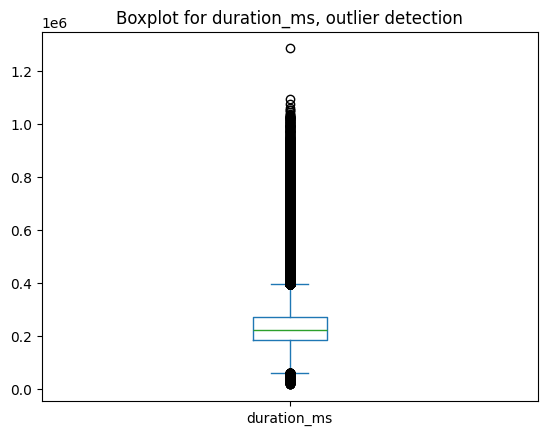

In [30]:
spotify_df['duration_ms'].plot.box(title="Boxplot for duration_ms, outlier detection")

Despite the number of outliers seen in the boxplot, the group decided to not remove these songs as the boxplot shows that it is possible to have songs of that length. Removing the songs outside the box will destroy the data.

In [31]:
spotify_df['tempo'].value_counts()

tempo
120.012    100
119.999     96
120.006     95
120.001     89
120.004     88
          ... 
131.544      1
75.395       1
119.303      1
186.012      1
178.292      1
Name: count, Length: 103453, dtype: int64

<Axes: title={'center': 'Boxplot for tempo, outlier detection'}>

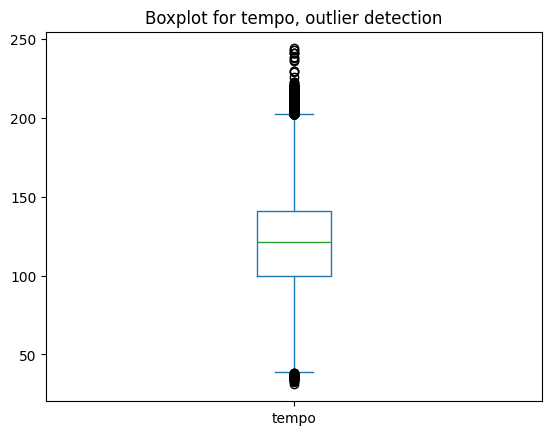

In [32]:
spotify_df['tempo'].plot.box(title="Boxplot for tempo, outlier detection")

Similar to duration_ms, removing the outliers will destroy the data. It's possible that songs will have a high tempo (shown by the boxplot), and these should be considered in this study.

#### **Find unique genres to check if all representation are valid** ####

In [33]:
spotify_df['genre'].unique()

<StringArray>
[   'Hip-Hop',       'Rock',  'Classical',        'Pop',      'Blues',
    'Country',       'Folk', 'Electronic',       'Jazz',        'R&B']
Length: 10, dtype: str

In [34]:
spotify_df['genre'].value_counts()

genre
Rock          130710
Pop            47954
Electronic     44625
Country        31353
Folk           30706
Hip-Hop        29292
R&B            19439
Jazz           11406
Blues          10385
Classical       7155
Name: count, dtype: int64

#### **Conversion of miliseconds in duration to seconds for easier digestion** ####

In [35]:
spotify_df['duration_ms'] = spotify_df['duration_ms'] * 0.001
spotify_df['duration_ms']

0         114.000
2         178.533
7         237.973
9         226.200
10        157.667
           ...   
491627    477.294
491628    356.752
491629    191.922
491630    159.267
491631    179.573
Name: duration_ms, Length: 363025, dtype: float64

#### FINAL STUCTURE + EXPORT TO NEW CSV FOR SAFETY

128594 rows filtered out. 363025 observations left.

In [36]:
spotify_df.info()

<class 'pandas.DataFrame'>
Index: 363025 entries, 0 to 491631
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   name                    363025 non-null  str    
 1   album_name              363025 non-null  str    
 2   artists                 363025 non-null  str    
 3   danceability            363025 non-null  float64
 4   energy                  363025 non-null  float64
 5   loudness                363025 non-null  float64
 6   mode                    363025 non-null  int64  
 7   speechiness             363025 non-null  float64
 8   instrumentalness        363025 non-null  float64
 9   valence                 363025 non-null  float64
 10  tempo                   363025 non-null  float64
 11  duration_ms             363025 non-null  float64
 12  year                    363025 non-null  int64  
 13  genre                   363025 non-null  str    
 14  popularity              363025 non-n

EXPORT TO NEW CSV FILE FOR SAFETY (songs2.csv)

In [37]:
spotify_df.to_csv('songs2.csv', index=False)

## **4. Research Question and Exploratory Data Analysis** ##

For the group's EDA, we determined the following to be features relevant enough to be analyzed:

In [38]:
numeric_features = [
    'danceability', 
    'energy', 
    'loudness', 
    'speechiness',
    'instrumentalness', 
    'valence', 
    'tempo', 
    'duration_ms',
    'popularity', 
    'total_artist_followers', 
    'avg_artist_popularity'
]

Additionally, due to the large size of dataset's population, the group decided to use a sample of 1% of the population for the sake of visual clarity in certain plots. 

In [39]:
sample = len(spotify_df) // 100
sample
spotify_sample = spotify_df.sample(sample, random_state=8)

#### **1. What is the distribution of the genres in the dataset?** ####

In [40]:
genre_count = spotify_df['genre'].value_counts()
genre_summary = pd.DataFrame(genre_count).reset_index()
genre_summary.columns = ['Genre', 'Count']
genre_summary['Percentage'] = (genre_summary['Count'] / genre_summary['Count'].sum()) * 100
genre_summary

,Genre,Count,Percentage
0,Rock,130710,36.005785
1,Pop,47954,13.209559
2,Electronic,44625,12.292542
3,Country,31353,8.636595
4,Folk,30706,8.458371
5,Hip-Hop,29292,8.068866
6,R&B,19439,5.354728
7,Jazz,11406,3.141932
8,Blues,10385,2.860685
9,Classical,7155,1.970939


The statistics above show how prevalent the "Rock" genre is considering that it has the most amount of songs by a large margin with 130,718 entries, consisting of about 36.01% of the entire dataset's population. 

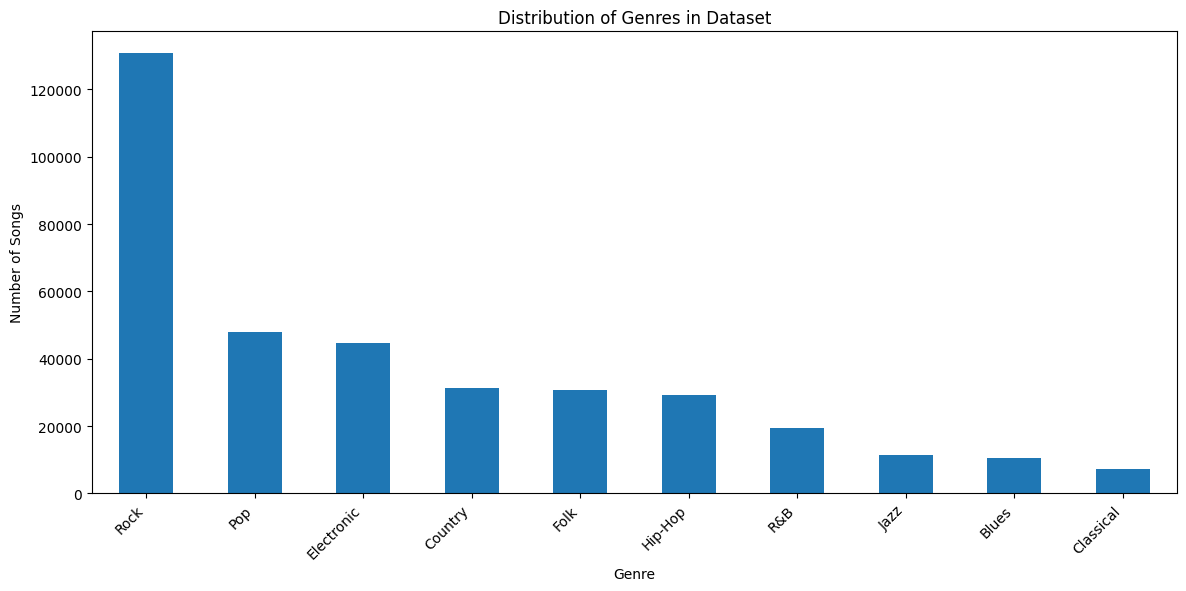

In [41]:
genre_count.plot.bar(figsize=(14,6))
plt.title('Distribution of Genres in Dataset')
plt.xlabel('Genre')
plt.ylabel('Number of Songs')
plt.xticks(rotation=45, ha='right')
plt.show()

The bar graph reflects the "Rock" genre's dominance of the dataset population. It also displays how close some genres are in terms of count, such as with the genres "Country", "Folk", and "Hip Hop". Possible inquiries arise on whether quantity is an indicator of a genre's popularity.  

#### **2. Are there correlations between the variables?** ####

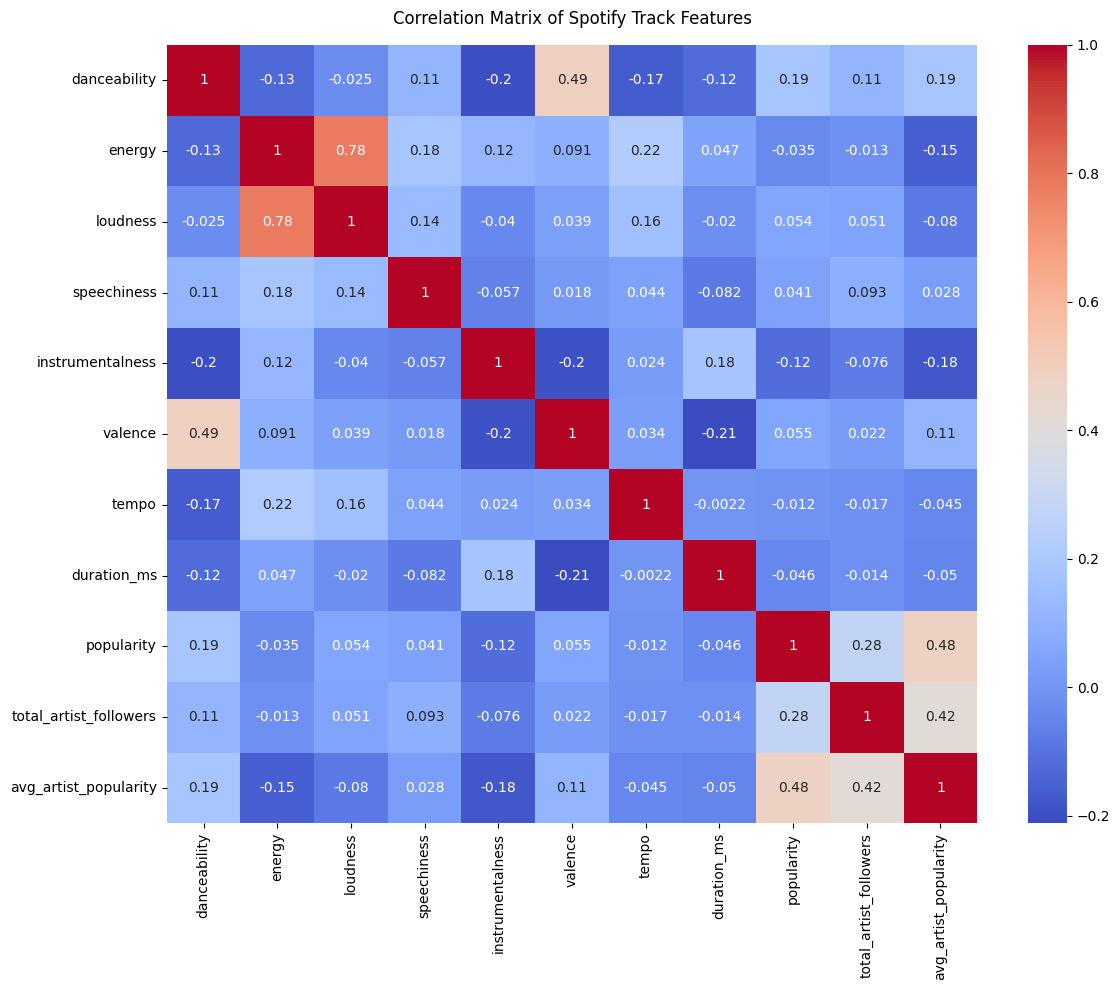

In [42]:
correlation = spotify_df[numeric_features].corr()
plt.figure(figsize=(12, 10))
sb.heatmap(correlation, cmap='coolwarm', annot=True)
plt.title('Correlation Matrix of Spotify Track Features', fontsize=12, pad=15)
plt.tight_layout()
plt.show()

From the heat map, the group deduced that a majority of the variables do not have a particularly strong correlation to one another. The variables that do have a high r value do make sense, such as "loudness" with "energy" (louder the song, the higher the energy) and "popularity" with "avg_artist_popularity" (the more popular the artist, the more popular their songs). as such, it is safe to say that outside of the obvious strong correlations, the variables do not have a strong influence on one another. 

#### **3. Are there correlations between the variables and a song's popularity?** ####

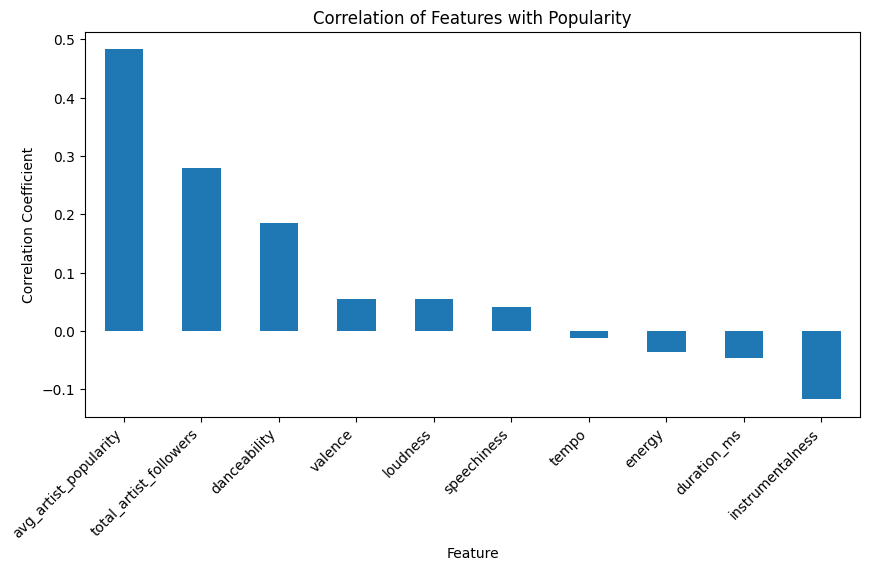

In [43]:
popularity_correlation = correlation[['popularity']].drop('popularity').sort_values('popularity', ascending=False)

popularity_correlation.plot.bar(figsize=(10, 5), legend=False)
plt.title('Correlation of Features with Popularity', fontsize=12)
plt.xlabel('Feature')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=45, ha='right')
plt.show()

The bar plot above corresponds to the correlation coefficients of each variable to popularity. At a first glance, it woud seem that "avg_artist_populartity" has the strongest relationship. However, considering that it is still less than 0.5, the strength is noticeable at best. Pearson r coefficient was used to measure the following data as all variables involved have continuous numeric values and it quantifies the strength and direction of the relationship between each feature and popularity.

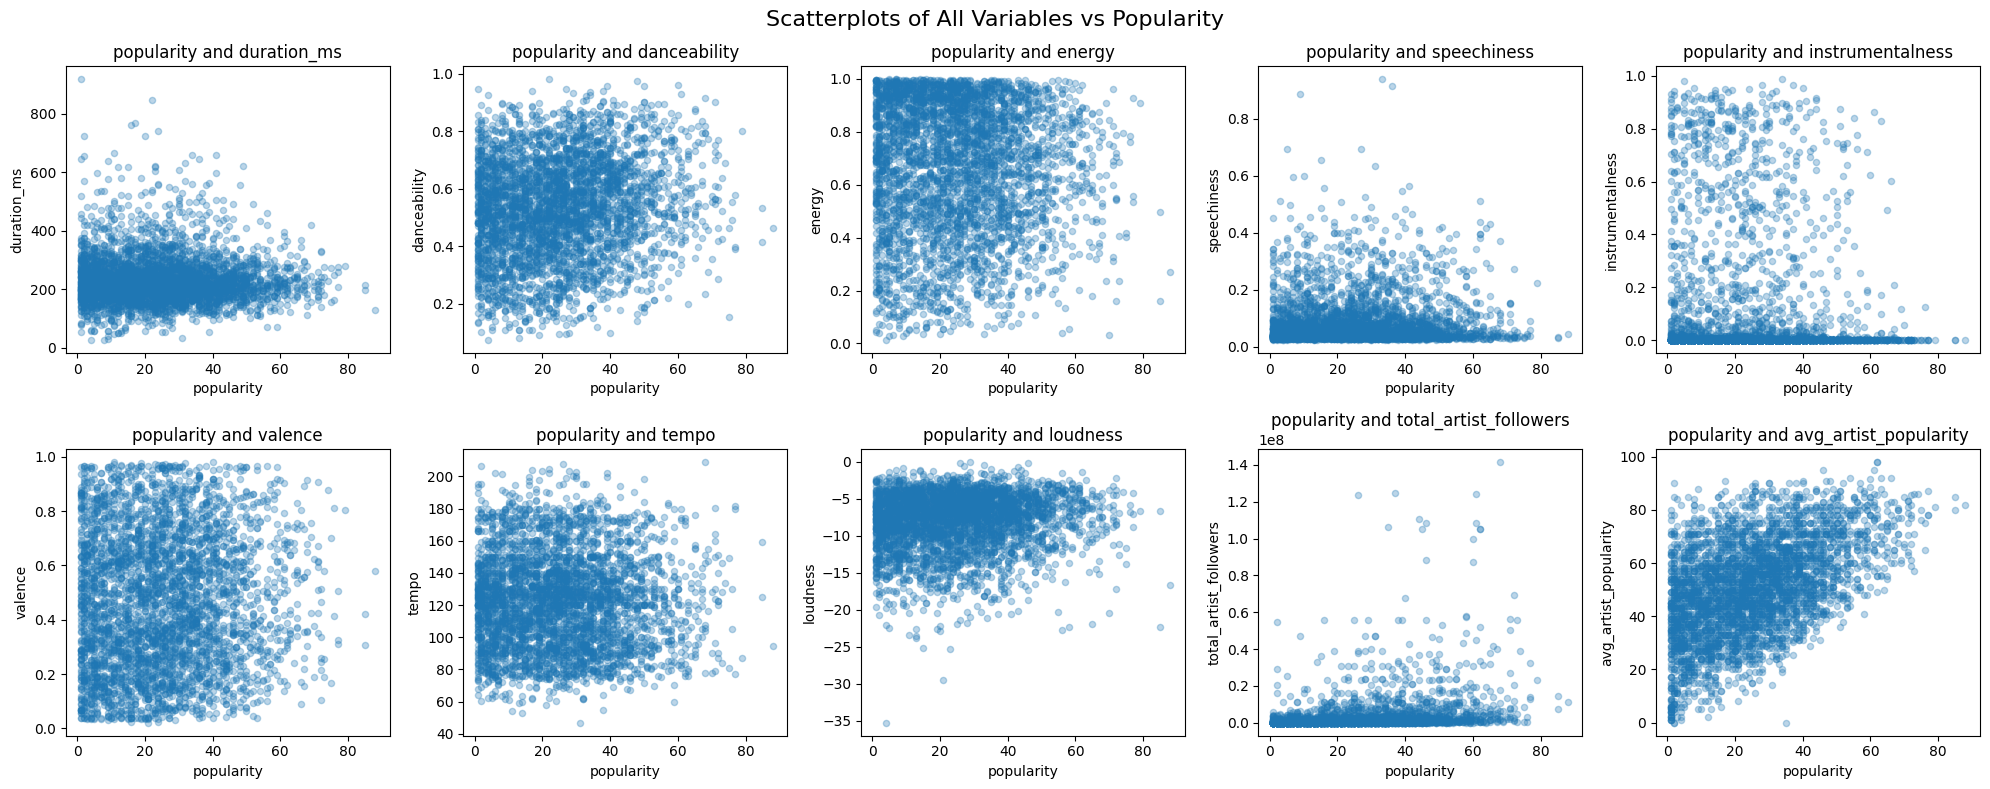

In [44]:
audio_features = ['duration_ms', 'danceability', 'energy', 'speechiness',
                  'instrumentalness', 'valence', 'tempo', 'loudness',
                  'total_artist_followers', 'avg_artist_popularity']

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(audio_features):
    spotify_sample.plot.scatter(x='popularity', y=feature, alpha=0.3, ax=axes[i])
    axes[i].set_title(f'popularity and {feature}')
    axes[i].set_xlabel('popularity')
    axes[i].set_ylabel(feature)

plt.suptitle('Scatterplots of All Variables vs Popularity', fontsize=16)
plt.tight_layout()
plt.show()

Based on the scatter plots, it can be confirmed that a majority of the variables have little to no correlation with popularity. It is also clear that a high amount of variability is at play, meaning popularity does not seem to be properly tied to any specific feature. 

Given the EDA performed, the group was able to agree on the following research question:

**"To what extent do variables such as audio characteristics, genre, and artist metrics contribute to the popularity of a song on Spotify?"**

The group believes that this question is worth investigating as it can provide thought-provoking observations on what makes a song popular on a worldwide scale. By intersecting audio features and musical metrics with statistical analysis and testing, the project aims to determine if there are trends and relationships that can influence how engaging a musical work can be on a large audience.

## **5. Data Mining** ##

In [45]:
# Read pre-processed dataset
pre_processed_spotify_df = pd.read_csv('songs2.csv')

The group has chosen k-means clustering as the data mining method to create structure in the data. This method will allow us to group songs with similar track features (e.g. cluster 0 has songs with high danceability, high tempo, etc.) and explore patterns in their popularity values. These patterns may yield possible relationships between popularity and different features. Clustering will also handle which range of values will go to a certain cluster, which is a more accurate method than manual binning.


The group did not use hierarchical clustering as this is computationally slow due to computing the distance between every pair of points at the start, which is not viable for the large dataset in this study. The group also used `Kmeans` library of the `scikit-learn` package for efficiency purposes.

In [46]:
# install scikit-learn first before running the following code
from sklearn.cluster import KMeans

Clustering by multiple features was done because a song is not just based on 1 characteristic. Several characteristics work together to form the song, not just isolated features. In other terms, **“song personas”** were utilized.

Due to the various possible of value ranges features have (e.g. 0.0 to 1.0 for danceability but -60dBs to 0dBs for loudness), scaling was applied to values to avoid biases on features (giving priority to a feature just because the gap is bigger due to the nature of values). The library `StandardScaler` was used to properly scale the values, utilizing z-score standardization which uses the original value, mean and standard deviation of the column to compute for the z-score.

In [47]:
# install scikit-learn first before running the following code
from sklearn.preprocessing import StandardScaler

In [48]:
features_to_be_scaled = ['danceability', 'energy', 'loudness', 'speechiness', 'instrumentalness', 
                         'valence', 'tempo', 'duration_ms']

# initialize the StandardScaler
scaler = StandardScaler()

# scale the features
scaled_features = scaler.fit_transform(pre_processed_spotify_df[features_to_be_scaled])

scaled_spotify_df = pre_processed_spotify_df.copy()

# put scaled features into a new DataFrame because the output of StandardScaler is a numpy array
scaled_spotify_df[features_to_be_scaled] = pd.DataFrame(scaled_features, columns=features_to_be_scaled)

To determine the number of clusters `k`, the elbow method was utilized. The method measures the sum of squares within a cluster (or inertia) for different values of `k`. The inertia is plotted in a graph and the `k` value that has a smaller turning curve is the chosen number of clusters.

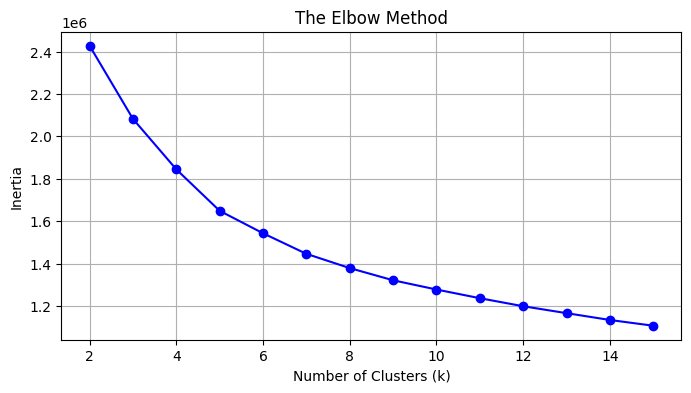

In [49]:
# Assign the scaled features to a new variable for further analysis
X_scaled = scaled_spotify_df[features_to_be_scaled]

inertia = []
k_range = range(2,16) # adjust max number when needed

# measuring inertia for different values of k
for k in k_range:

    # initialize KMeans for elbow method
    kmeans_elbow = KMeans(n_clusters=k, random_state=42, n_init=10)

    # calculate and append inertia
    kmeans_elbow.fit(X_scaled)
    inertia.append(kmeans_elbow.inertia_)

# Plot k-value - inertia relationships 
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker='o', color='b')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('The Elbow Method')
plt.grid(True)
plt.show()


From the graph above, we can see that 8 is the appropriate `k` value as the curve has smoothen there and inertia in that area has minimal differences compared to close values of `k`.

K-Means Clustering Algorithm of song according to their song personas with sklearn's KMeans library.

In [50]:
number_of_clusters = 8

# initialize KMeans algorithm with a setted random state and 10 iterations
kmeans = KMeans(n_clusters=number_of_clusters, random_state=42, n_init=10)

# predict cluster assignments
cluster_labels = kmeans.fit_predict(X_scaled)

# attach cluster labels to an additional column in the dataframe
scaled_spotify_df['cluster'] = cluster_labels
pre_processed_spotify_df['cluster'] = cluster_labels

### **Clustering Results** ###

Check number of songs per cluster

In [51]:

number_of_songs_in_cluster = scaled_spotify_df['cluster'].value_counts().sort_index()
print(number_of_songs_in_cluster)

cluster
0    15342
1    69419
2    69072
3    53934
4    26470
5    31522
6    44772
7    52494
Name: count, dtype: int64


Calculate average musical features for each cluster to determine the music persona.

In [52]:
persona_profiles = scaled_spotify_df.groupby('cluster')[features_to_be_scaled].mean().round(2)
persona_profiles

,danceability,energy,loudness,speechiness,instrumentalness,valence,tempo,duration_ms
cluster,,,,,,,,
0,-0.59,0.02,-0.22,-0.24,0.55,-0.62,0.03,2.98
1,0.77,0.45,0.48,-0.25,-0.33,1.05,-0.13,-0.24
2,-0.33,0.53,0.57,-0.16,-0.30,-0.66,-0.44,0.03
3,0.70,-0.84,-0.76,-0.34,-0.31,0.59,-0.25,-0.30
4,0.86,0.03,0.15,2.78,-0.39,0.34,-0.16,-0.26
5,-0.57,0.52,0.14,-0.10,2.74,-0.53,0.09,0.18
6,-0.53,-1.66,-1.50,-0.49,-0.19,-0.83,-0.44,-0.11
7,-0.77,0.64,0.58,0.04,-0.30,-0.10,1.40,-0.17


Personas are extracted using the mean of the scaled z-score of each feature. Since they are standardized, negative values represent below average values for that feature, while positive values represent the above average.

**Cluster 0:**
- low danceability, medium energy, low loudness, low speechiness, high instrumentalness, low valence, medium tempo, long duration
- contains ambient and cinematic music that is meant to be played in the background, such as movie soundtracks or classical pieces.

**Cluster 1:**
- high danceability, high energy, high loudness, low speechiness, low instrumentalness, high valence, low tempo, short duration
- includes upbeat pop music that would typically be heard in parties and social events

**Cluster 2:**
- low danceability, high energy, high loudness, low speechiness, low instrumentalness, low valence, low tempo, medium duration
- contains rock music and generally angsty pieces

**Cluster 3:**
- high danceability, low energy, low loudness, low speechiness, low instrumentalness, high valence, low tempo, short duration
- consists of R&B and acoustic pop music that people can dance to, but are not necessarily meant to be high energy

**Cluster 4:**
- high danceability, medium energy, high loudness, high speechiness, low instrumentalness, high valence, low tempo, short duration
- consists hiphop and rap music that encourages people to move to their beats

**Cluster 5:**
- low danceability, high energy, high loudness, low speechiness, high instrumentalness, low valence, high tempo, long duration
- consists of EDM and instrumental electronic tracks

**Cluster 6:**
- low danceability, low energy, low loudness, low speechiness, low instrumentalness, low valence, low tempo, short duration
- made up of somber, melancholic, and emotional pieces

**Cluster 7:**
- low danceability, high energy, high loudness, high speechiness, low instrumentalness, low valence, high tempo, short duration
- made up of fast-paced music that can be used during exercise or high energy scenarios

Check genre values of each cluster

In [53]:
pd.set_option('display.max_rows', None)
genre_of_each_cluster = scaled_spotify_df.groupby('cluster')['genre'].value_counts()
print(genre_of_each_cluster)

cluster  genre     
0        Rock           8901
         Electronic     2493
         Pop            1101
         Folk            662
         R&B             627
         Blues           599
         Jazz            310
         Country         302
         Classical       210
         Hip-Hop         137
1        Rock          15739
         Pop           13275
         Electronic    11176
         Country        7198
         Folk           7171
         Hip-Hop        5701
         R&B            5533
         Blues          2135
         Jazz            806
         Classical       685
2        Rock          37871
         Electronic    10282
         Pop            7405
         Country        3827
         Hip-Hop        2896
         R&B            2488
         Folk           2466
         Blues           885
         Classical       734
         Jazz            218
3        Rock           9112
         Pop            8866
         Country        8739
         Folk          

To see if a persona has a positive or negative relationship with popularity, the median popularity of each cluster or persona was used; if a median popularity of a cluster is higher than the global median, that cluster is said to have a positive relationship with popularity, and vice versa.

In [56]:
# get median of popularity of whole preprocessed dataset
global_median_popularity = pre_processed_spotify_df['popularity'].median()

# groups songs by cluster and calculates the popularity median, popularity mean, and track count.
popularity_analysis_per_cluster = scaled_spotify_df.groupby('cluster')['popularity'].agg(
    median_popularity='median',
    mean_popularity='mean',
    track_count='count'
)

# Calculate difference from global popularity
popularity_analysis_per_cluster['diff_from_global_popularity'] = popularity_analysis_per_cluster['median_popularity'] - global_median_popularity
print(f"Global Baseline Popularity: {global_median_popularity}\n")
print(popularity_analysis_per_cluster.sort_values(by='median_popularity', ascending=False))

Global Baseline Popularity: 23.0

         median_popularity  mean_popularity  track_count  \
cluster                                                    
4                     29.0        29.855043        26470   
1                     26.0        27.106037        69419   
3                     24.0        25.902047        53934   
2                     23.0        24.647093        69072   
7                     22.0        24.220768        52494   
6                     22.0        23.628630        44772   
0                     19.0        20.803611        15342   
5                     17.0        19.909428        31522   

         diff_from_global_popularity  
cluster                               
4                                6.0  
1                                3.0  
3                                1.0  
2                                0.0  
7                               -1.0  
6                               -1.0  
0                               -4.0  
5             

Based on the results, it can be said that cluster 4 (hiphop and rap) is far and away the most commerically popular classification of music based on the data utilized, with cluster 1 (pop) and Cluster 3 (R&B and acoustic) still being decently popular when compared to the baseline. From cluster 4, this means very loud songs accompanied by its high danceability and high volume of words with a slow tempo have a great relationship with popularity.

Clusters 7 (fast-paced) and 6 (somber) are 1 unit less than the the baseline, making them somewhat niche but not totally obscure from mainstream audiences. Meanwhile, clusters 0 (ambient) and 5 (EDM and electro) have the largest negative difference from the baseline, making them incredibly niche and targeted for certain audiences. Cluster 5 songs focus on loudness and instruments with a faster pace despite no words and complex rhythms. Cluster 2 (rock) shares the same value as the baseline, meaning it performs pretty normally and is neither popular nor unpopular in the eyes of the general listening audience.

## **6. Statistical Inferences** ##

### Chi-Square Goodness of Fit

This test was done in order to verify whether or not the sample the group used during the Exploratory Data Analysis portion is representative of the full dataset as the group utilized samples during visualization. For this test an alpha value (a) of 0.05 will be used to determine whether to reject or fail to reject the null hypothesis. 

`Ho`: The genre distribution of the sample is consistent with the genre distribution of the full dataset.\
\
`Ha`: The genre distribution of the sample is significantly different to the genre distribution of the full dataset.

The chi-square goodness of fit test determines whether the sample of categorical data used accurately represents the entire population or not. This test is very much needed to verify the accuracy of the samples used during our exploratory data analysis section as only 1% of the entire data was used here.

In [54]:
genre_population = spotify_df['genre'].value_counts(normalize=True)
genre_sample_count = spotify_sample['genre'].value_counts()
genre_population = genre_population[genre_sample_count.index]
expected_counts = genre_population * len(spotify_sample)
observed_counts = genre_sample_count
chi2_stat, p_value = chisquare(f_obs=observed_counts, f_exp=expected_counts)

In [55]:
print(f"Chi-square statistic: {chi2_stat:.2f}")
print(f"p-value: {p_value:.4f}")

Chi-square statistic: 15.57
p-value: 0.0765


We can see that the test provided a chi-square statistic of 15.57 and a p-value of 0.0765. Since the p-value of the test is greater than a (0.0765 > 0,05), we fail to reject the null hypothesis. With this in mind, there is sufficient evidence to show that there is no significant difference with the sample and the full dataset.

### Chi-Square Test of Independence

Chi-square test of independence was done to observe the relationship between the genre and the popularity of a song. For this test, the popularity scores have been separated into three different tiers (low, medium, and high) through K-means clustering. An alpha value of 0.05 was used for hypothesis testing.

`Ho`: Genre and popularity tier are independent of each other.\
\
`Ha`: Genre and popularity tier have a significant relationship.

The chi square test of independence was the most viable option to conduct this test as it looks for any significant relationships between two different categorical variables. Genre is already a categorical variable with 10 different  categories. Popularity on the other hand is a continuous variable, and in order to convert it into a categorical variable, K-means clustering was utilized in order to separate the popularity scores into three different tiers being: low, medium, and high.

In [56]:
popularity_values = spotify_df[['popularity']]
kmeans_popularity = KMeans(n_clusters=3, random_state=8, n_init=10)
spotify_df['popularity_tier'] = kmeans_popularity.fit_predict(popularity_values)
tier_names = {1: 'Low', 2: 'Medium', 0: 'High'}
spotify_df['popularity_tier'] = spotify_df['popularity_tier'].map(tier_names)
spotify_df.groupby('popularity_tier')['popularity'].agg(['min', 'max', 'mean', 'count'])

,min,max,mean,count
popularity_tier,,,,
High,1,20,10.378518,160156
Low,21,41,30.029613,144023
Medium,42,98,52.005659,58846


Create contingency table to perform the test

In [57]:
contingency = pd.crosstab(spotify_df['genre'], spotify_df['popularity_tier'])
contingency

popularity_tier,High,Low,Medium
genre,,,
Blues,5748,3786,851
Classical,3255,2837,1063
Country,12770,13560,5023
Electronic,18940,18940,6745
Folk,14180,12586,3940
Hip-Hop,7085,12756,9451
Jazz,5848,4052,1506
Pop,19253,18543,10158
R&B,6616,8625,4198


In [58]:
chi2_stat, p_value, dof, expected = chi2_contingency(contingency)

print(f"Chi-square statistic: {chi2_stat:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.4f}")

Chi-square statistic: 13701.61
Degrees of freedom: 18
p-value: 0.0000


Since the chi square statistic is extremely large and p-value is extremely low, we reject the null hypothesis indicating that there is a significant association between genre and popularity tier. 

### ANOVA Testing

Check sample size per genre

In [59]:
genre_groups = [spotify_df.loc[spotify_df['genre'] == g, 'popularity'] for g in spotify_df['genre'].unique()]
print("Sample size per genre:")
print(genre_count)
print()

Sample size per genre:
genre
Rock          130710
Pop            47954
Electronic     44625
Country        31353
Folk           30706
Hip-Hop        29292
R&B            19439
Jazz           11406
Blues          10385
Classical       7155
Name: count, dtype: int64



For the ANOVA testing, one-way ANOVA was used to check if the average popularity among different genres are different from one another.

`Ho`: All 10 genres have the exact same average popularity score.\
\
`Ha`: At least 1 genre has a significantly different average popularity score.


In [62]:
f_stat, p_value = f_oneway(*genre_groups)

alpha = 0.05
print(f"F-statistic: {f_stat:.3f}")
print(f"p-value: {p_value:.4f}")
print(f"Significance level: {alpha}")

F-statistic: 1672.211
p-value: 0.0000
Significance level: 0.05


Since the `F-statistic` is absurdly large, there is a significant difference between different genre groups. Due to the `p-value` being lower than `alpha`, the null hypothesis is rejected. 

To check which genres have different levels of popularity, Bonferroni-correction pairwise t-tests were conducted to avoid false positives.

In [61]:
if p_value < alpha:
    genres = spotify_df['genre'].unique()
    pairs = list(combinations(genres, 2))
    alpha_corrected = alpha / len(pairs)

    print(f"Number of Comparisons: {len(pairs)}")
    print(f"Bonferroni Correction: {alpha_corrected:.4f}")
    print()

    posthoc_results = []
    for grp1, grp2 in pairs:
        group1 = spotify_df.loc[spotify_df['genre'] == grp1, 'popularity']
        group2 = spotify_df.loc[spotify_df['genre'] == grp2, 'popularity']
        t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)
        significant = p_val < alpha_corrected
        posthoc_results.append({
            'Genre 1': grp1,
            'Genre 2': grp2,
            'Mean Diff': group1.mean() - group2.mean(),
            't-statistic': t_stat,
            'p-value': p_val,
            'Significant (Bonferroni)': significant
        })

    posthoc_df = pd.DataFrame(posthoc_results).sort_values('p-value')
    print(posthoc_df.to_string(index=False))

Number of Comparisons: 45
Bonferroni Correction: 0.0011

   Genre 1    Genre 2  Mean Diff  t-statistic       p-value  Significant (Bonferroni)
   Hip-Hop       Rock  11.003448    99.426581  0.000000e+00                      True
   Hip-Hop  Classical   9.451375    44.553334  0.000000e+00                      True
   Hip-Hop        Pop   6.427378    49.210064  0.000000e+00                      True
   Hip-Hop      Blues  13.350908    77.217050  0.000000e+00                      True
   Hip-Hop    Country   7.821643    58.084961  0.000000e+00                      True
   Hip-Hop       Folk   9.938708    74.617845  0.000000e+00                      True
   Hip-Hop Electronic   8.470267    67.542388  0.000000e+00                      True
   Hip-Hop       Jazz  11.210480    62.320977  0.000000e+00                      True
      Rock        Pop  -4.576071   -49.756682  0.000000e+00                      True
      Rock        R&B  -6.230099   -50.272491  0.000000e+00                      Tr

The group observed used the Mean Differences to check which genre has a higher popularity than the other (positive mean diff means genre 1 > genre 2, vice versa). Based from the results above, the ranking from highest mean popularity to lowest is:
1) Hip-Hop
2) R&B
3) Country, Pop
4) Electronic
5) Classical
6) Folk
7) Jazz, Rock
8) Blues

From the results above, two genre pairs did not have significant differences with one another (Classical - Folk, Rock - Jazz). The rest of the pairs had significant differences in the popularity mean due to `p-value` higher than the `alpha_adjusted`.